# Lab 1 Task 2

In [43]:
!pip install thop
!pip install torchsummary

In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import argparse
import os
import numpy as np
from torch.utils.data import random_split
from torch.utils.tensorboard import SummaryWriter
from thop import profile
from torchsummary import summary

In [45]:
# Check if CUDA is available
print(torch.cuda.is_available())

True


In [46]:
# Calculate mean and std of dataset
def get_mean_std(dataset, ratio=1):
    # Get mean and std by sample ratio
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=int(len(dataset)*ratio), shuffle=True, num_workers=2)

    data = next(iter(dataloader))[0]     # get the first iteration data
    mean = np.mean(data.numpy(), axis=(0,2,3))
    std = np.std(data.numpy(), axis=(0,2,3))
    return mean, std

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms.ToTensor())

train_mean, train_std = get_mean_std(train_dataset)
test_mean, test_std = train_mean, train_std
print(train_mean, train_std)
print(test_mean, test_std)

[0.4914005  0.4821572  0.44653055] [0.24703208 0.24348392 0.2615878 ]
[0.4914005  0.4821572  0.44653055] [0.24703208 0.24348392 0.2615878 ]


In [47]:
##### data augmentation & normalization #####
transform_train = transforms.Compose([
    # 同學實作部分：Add data augmentation here
    transforms.RandomCrop(32, padding=4), 
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), # Transform to tensor
    transforms.Normalize(mean=train_mean, std=train_std), # Normalization
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=test_mean, std=test_std),
])

In [48]:
# Dataset
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
test_ds = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

image, label = trainset[0]
print("image shape: ", image.shape)

# Split validation dataset
torch.manual_seed(43)     # Ensure reproducibility
val_size = 5000       # Take 5000 images as validation set
train_size = len(trainset) - val_size
train_ds, val_ds = random_split(trainset, [train_size, val_size])
print("train length: ", len(train_ds))
print("val length: ", len(val_ds))
print("test length: ", len(test_ds))

# Declare batch size
# 學生實作部分：Set batch size
BATCH_SIZE = 128
trainloader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
valloader = torch.utils.data.DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
testloader = torch.utils.data.DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

image shape:  torch.Size([3, 32, 32])
train length:  45000
val length:  5000
test length:  10000


In [49]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(BasicBlock, self).__init__()
        # 學生實作部分：Define the two convolutional layers and the shortcut connection
        # The CONV in ResNet is a combination of convolution + batch normalization + activation
        # __init__ is to instance each layer class. 
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)
        self.relu  = nn.ReLU(inplace=True)
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)
        
        self.shortcut = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False), 
            nn.BatchNorm2d(out_channels)) if ((stride != 1) or (in_channels != out_channels)) else nn.Sequential()

    def forward(self, x):
        # 學生實作部分：Define the forward pass using convolutional layers and the shortcut connection
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        
        out = self.conv2(out)
        out = self.bn2(out)
        
        return self.relu(out + self.shortcut(x))

class ResNet18(nn.Module):
    def __init__(self, num_classes=1000):
        super(ResNet18, self).__init__()
        # 學生實作部分：Define the ResNet-18 architecture using BasicBlock
        # !Note: O = \lfloor\frac{I-K+2P}{S}\rfloor + 1
        
        self.in_channels = 64
        
        self.conv = nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False) 
        self.bn1  = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        
        # self.pool1 = nn.MaxPool2d(3, stride=2, padding=1)
        
        self.layer1 = self._make_layer(BasicBlock, 64,  2, 1)
        self.layer2 = self._make_layer(BasicBlock, 128, 2, 2)
        self.layer3 = self._make_layer(BasicBlock, 256, 2, 2)
        self.layer4 = self._make_layer(BasicBlock, 512, 2, 2)
        
        self.pool2 = nn.AdaptiveAvgPool2d((1, 1))
        self.fc    = nn.Linear(512, num_classes)


    def _make_layer(self, block, out_channels, num_blocks, stride):
        # 學生實作部分：Instantiate "num_blocks" BasicBlock to form a set of conv layer
        layers     = []
        strides    = [1 for _ in range(num_blocks)]
        strides[0] = stride
        
        for s in strides:
            layers.append(block(self.in_channels, out_channels, s))
            self.in_channels = out_channels

        return nn.Sequential(*layers)

    def forward(self, x):
        # 學生實作部分：Define the forward pass of ResNet-18
        out = self.conv(x)
        out = self.bn1(out)
        out = self.relu(out)
        # out = self.pool1(out)
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.pool2(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)
        
        return out

In [50]:
# Create SummaryWriter
writer = SummaryWriter("../tensorboard")

model = ResNet18(num_classes=10)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
# Print model summary
# summary(model, (3, 224, 224))
summary(model, (3, 32, 32))

# Calculate FLOPs and Params
dummy_input = torch.randn(1, 3, 32, 32).to(device)
flops, params = profile(model, inputs=(dummy_input, ))
print(f"FLOPs: {flops/1e6:.2f} MFLOPs")
print(f"Params: {params/1e6:.2f} M")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,864
       BatchNorm2d-5           [-1, 64, 32, 32]             128
              ReLU-6           [-1, 64, 32, 32]               0
            Conv2d-7           [-1, 64, 32, 32]          36,864
       BatchNorm2d-8           [-1, 64, 32, 32]             128
              ReLU-9           [-1, 64, 32, 32]               0
       BasicBlock-10           [-1, 64, 32, 32]               0
           Conv2d-11           [-1, 64, 32, 32]          36,864
      BatchNorm2d-12           [-1, 64, 32, 32]             128
             ReLU-13           [-1, 64, 32, 32]               0
           Conv2d-14           [-1, 64,

In [51]:
# Setting parameter
EPOCH = 40
pre_epoch = 0
lr = 1e-3

# 同學可以根據自己需求調整optimizer, criterion與lr_scheduler
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCH)

best_model_path = 'best_resnet18.pth'

# Record training and validation metrics
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []
best_val_acc = 0.0

# Training and validation loop
for epoch in range(pre_epoch, EPOCH):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    # 學生實作部分：Complete the training and validation loop
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * labels.size(0)
        _, predicted = outputs.max(1) #? max(1) would return the values and indices along 1st dimension i.e., class 
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    scheduler.step()
    
    train_loss = running_loss / total
    train_acc = 100. * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    
    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in valloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * labels.size(0)
            _, predicted = outputs.max(1) 
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()
    
    val_loss = val_loss / val_total
    val_acc = 100. * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
            
    # 儲存最佳模型
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)


    print(f"Epoch [{epoch+1}/{EPOCH}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")


Epoch [1/40] Train Loss: 1.4939 | Train Acc: 45.31% | Val Loss: 1.1865 | Val Acc: 57.44%
Epoch [2/40] Train Loss: 1.0031 | Train Acc: 64.04% | Val Loss: 1.2090 | Val Acc: 59.44%
Epoch [3/40] Train Loss: 0.7992 | Train Acc: 71.68% | Val Loss: 0.8040 | Val Acc: 72.28%
Epoch [4/40] Train Loss: 0.6544 | Train Acc: 77.11% | Val Loss: 0.6486 | Val Acc: 78.02%
Epoch [5/40] Train Loss: 0.5618 | Train Acc: 80.32% | Val Loss: 0.6673 | Val Acc: 77.58%
Epoch [6/40] Train Loss: 0.5044 | Train Acc: 82.66% | Val Loss: 0.5383 | Val Acc: 81.50%
Epoch [7/40] Train Loss: 0.4449 | Train Acc: 84.69% | Val Loss: 0.5616 | Val Acc: 80.96%
Epoch [8/40] Train Loss: 0.4087 | Train Acc: 85.66% | Val Loss: 0.4621 | Val Acc: 83.90%
Epoch [9/40] Train Loss: 0.3711 | Train Acc: 87.15% | Val Loss: 0.5354 | Val Acc: 82.18%
Epoch [10/40] Train Loss: 0.3405 | Train Acc: 88.31% | Val Loss: 0.5004 | Val Acc: 83.30%
Epoch [11/40] Train Loss: 0.3089 | Train Acc: 89.27% | Val Loss: 0.4063 | Val Acc: 86.06%
Epoch [12/40] Train

In [52]:
# Load the best model and evaluate on the test set
model.load_state_dict(torch.load(best_model_path, map_location=device))

model.eval()

test_correct = 0
test_total = 0
with torch.no_grad():
    for test_inputs, test_labels in testloader:
        test_inputs, test_labels = test_inputs.to(device), test_labels.to(device)
        test_outputs = model(test_inputs)
        _, test_predicted = test_outputs.max(1)
        test_total += test_labels.size(0)
        test_correct += test_predicted.eq(test_labels).sum().item()
test_accuracy = 100. * test_correct / test_total
print(f"Best Model Test Accuracy: {test_accuracy:.2f}%")

Best Model Test Accuracy: 92.21%


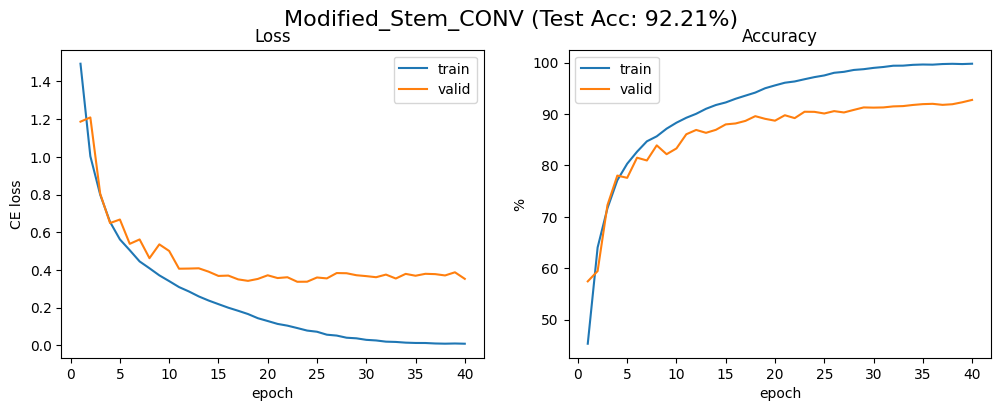

In [53]:
EXP_NAME = 'Modified_Stem_CONV'

##### Plot loss & accuracy graph #####
import matplotlib.pyplot as plt
# 學生實作部分：Plot training and validation loss and accuracy curves
epochs_range = range(1, len(train_losses) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, train_losses, label='train')
ax1.plot(epochs_range, val_losses, label='valid')
ax1.set_xlabel('epoch')
ax1.set_ylabel('CE loss')
ax1.set_title('Loss')
ax1.legend()

ax2.plot(epochs_range, train_accuracies, label='train')
ax2.plot(epochs_range, val_accuracies, label='valid')
ax2.set_xlabel('epoch')
ax2.set_ylabel('%')
ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle(f"{EXP_NAME} (Test Acc: {test_accuracy:.2f}%)", fontsize=16)

plt.savefig(f"{(EXP_NAME).lower()}.png", dpi=150, bbox_inches='tight')

plt.show()